<a href="https://colab.research.google.com/github/neox-alt/data-Science/blob/main/Pruning/Untitled3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import torch
import torch.nn as nn
import numpy as np
from transformers import ViTModel, ViTConfig, ViTImageProcessor

from torch.utils.data import DataLoader,Dataset

from torchvision import transforms
from PIL import Image
import time
import os
import json
from collections import defaultdict


In [2]:

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"using the device: {device}")

using the device: cpu


In [4]:
# getting the original model ViT base model before pruning from huggingface google/vit-base-patch16-224

from transformers import ViTForImageClassification, ViTImageProcessor

#This is the model that ew gonna use

MODEL_NAME = "google/vit-base-patch16-224"

#processor will download the image processing configurations need for the base model we are using

processor = ViTImageProcessor.from_pretrained(MODEL_NAME)


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

In [5]:
model = ViTForImageClassification.from_pretrained(MODEL_NAME, output_attentions = True , ignore_mismatched_sizes = True)

config.json:   0%|          | 0.00/69.7k [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

In [6]:
model = model.to(device)
model.eval()

ViTForImageClassification(
  (vit): ViTModel(
    (embeddings): ViTEmbeddings(
      (patch_embeddings): ViTPatchEmbeddings(
        (projection): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
      )
      (dropout): Dropout(p=0.0, inplace=False)
    )
    (encoder): ViTEncoder(
      (layer): ModuleList(
        (0-11): 12 x ViTLayer(
          (attention): ViTAttention(
            (attention): ViTSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
            )
            (output): ViTSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.0, inplace=False)
            )
          )
          (intermediate): ViTIntermediate(
            (dense): Linear(in_features=768, out_features=3072, bias=True)
            (intermed

README.md:   0%|          | 0.00/3.71k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/255M [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/85.1M [00:00<?, ?B/s]

data/contrast-00000-of-00001.parquet:   0%|          | 0.00/65.5M [00:00<?, ?B/s]

data/gaussian_noise-00000-of-00001.parqu(…):   0%|          | 0.00/116M [00:00<?, ?B/s]

data/impulse_noise-00000-of-00001.parque(…):   0%|          | 0.00/124M [00:00<?, ?B/s]

... (10 outputs left out)

Generating motion_blur split:   0%|          | 0/6300 [00:00<?, ? examples/s]

Generating pixelate split:   0%|          | 0/6300 [00:00<?, ? examples/s]

Generating spatter split:   0%|          | 0/6300 [00:00<?, ? examples/s]

Size    : 500 images
Classes : ['airplane', 'airport', 'baseball diamond', 'basketball court', 'beach', 'bridge', 'chaparral', 'church', 'circular farmland', 'cloud', 'commercial area', 'dense residential', 'desert', 'forest', 'freeway', 'golf course', 'ground track field', 'harbor', 'industrial area', 'intersection', 'island', 'lake', 'meadow', 'medium residential', 'mobile home park', 'mountain', 'overpass', 'palace', 'parking lot', 'railway', 'railway station', 'rectangular farmland', 'river', 'roundabout', 'runway', 'sea ice', 'ship', 'snowberg', 'sparse residential', 'stadium', 'storage tank', 'tennis court', 'terrace', 'thermal power station', 'wetland']


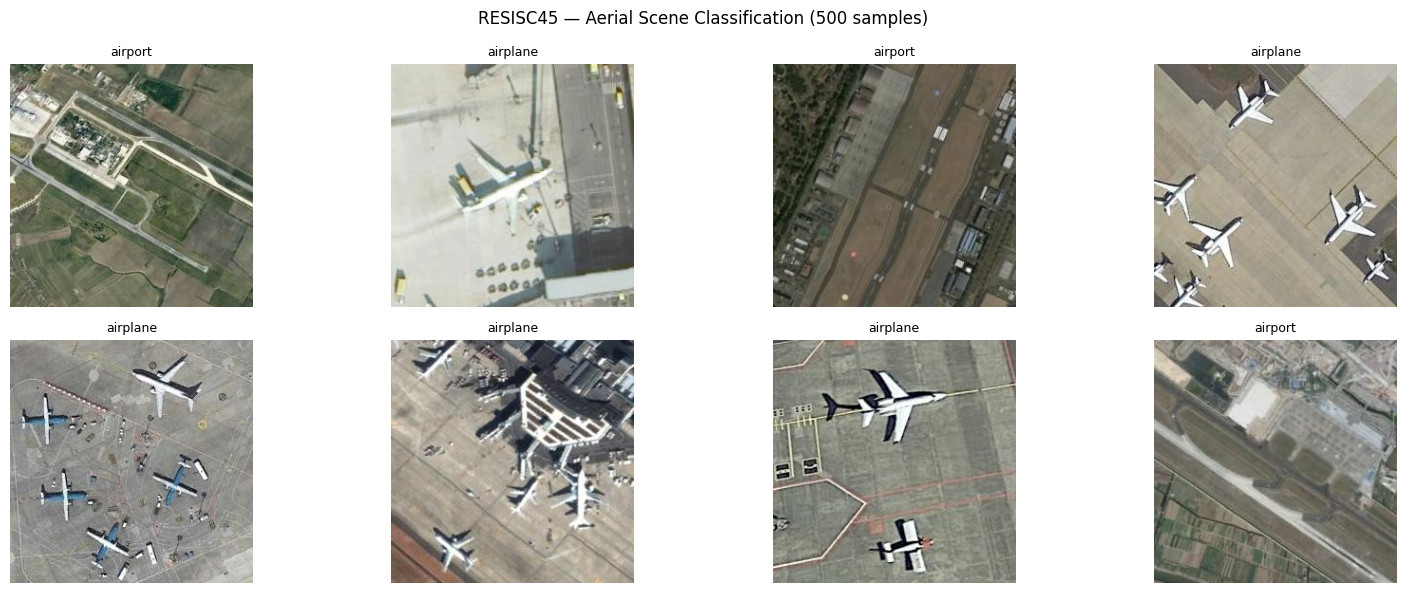

In [7]:
from datasets import load_dataset
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
import torch

# Use this one instead — no scripts, pure parquet
dataset = load_dataset("tanganke/resisc45", split="train[:500]")
dataset = dataset.shuffle(seed=42).select(range(500))  # ← shuffle first!


print(f"Size    : {len(dataset)} images")
print(f"Classes : {dataset.features['label'].names}")

# View samples
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
class_names = dataset.features['label'].names
for i, ax in enumerate(axes.flatten()):
    sample = dataset[i]
    ax.imshow(sample['image'])
    ax.set_title(class_names[sample['label']], fontsize=9)
    ax.axis('off')
plt.suptitle("RESISC45 — Aerial Scene Classification (500 samples)")
plt.tight_layout()
plt.show()


In [8]:
# DataLoaders ready for ViT pipeline
class AerialDataset(Dataset):
    def __init__(self, hf_data):
        self.data = hf_data
        self.transform = transforms.Compose([
            transforms.Resize((224, 224)),
            transforms.ToTensor(),
            transforms.Normalize([0.485, 0.456, 0.406],
                                 [0.229, 0.224, 0.225])
        ])
    def __len__(self): return len(self.data)
    def __getitem__(self, idx):
        s = self.data[idx]
        return self.transform(s['image'].convert('RGB')), s['label']

train_loader = DataLoader(AerialDataset(dataset.select(range(400))),
                          batch_size=16, shuffle=True)
val_loader   = DataLoader(AerialDataset(dataset.select(range(400, 500))),
                          batch_size=16, shuffle=False)

images, labels = next(iter(train_loader))
print(f"Batch shape : {images.shape}")   # [16, 3, 224, 224] ✅
print(f"Labels      : {labels.tolist()}")
print("Ready!")

Batch shape : torch.Size([16, 3, 224, 224])
Labels      : [0, 1, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0]
Ready!


In [9]:
def compute_attention_scores_per_head(model, dataloader, num_batches =5):
  model.eval()
  head_scores = defaultdict(lambda:[])

  with torch.no_grad():
    for batch_idx,(images,_) in enumerate(dataloader):
      if batch_idx >= num_batches :
        break

      images = images.to(device)

      outputs =model(images,output_attentions =True)

      attentions = outputs.attentions

      for layer_idx , layer_attn in enumerate(attentions):
        batch_size , num_heads, seq_len,_ = layer_attn.shape

        for head_idx in range(num_heads):
          head_attn = layer_attn[:,head_idx,:,:]

          #calculating the entropy per attention head

          attn_probs = head_attn + 1e-9
          entropy = -(attn_probs * torch.log(attn_probs)).sum(dim=-1).mean()

          #Now calculating the spatial variance per head

          spatial_var = head_attn.var(dim=-1).mean()

          # --- Combined domain-aware score ---
          # Low entropy + high spatial variance = important head for small objects
          # We invert entropy so higher score = more focused = more important
          score = spatial_var - (entropy * 0.1)
          head_scores[layer_idx].append(score.item())

  averaged_scores ={}
  for layer_idx in head_scores:
    scores_per_head = np.array(head_scores[layer_idx])
    num_heads = model.config.num_attention_heads
    scores_matrix = scores_per_head.reshape(-1, num_heads)
    averaged_scores[layer_idx] = scores_matrix.mean(axis=0)
  return averaged_scores




In [10]:
# Compute scores
head_importance = compute_attention_scores_per_head(model, val_loader, num_batches=3)

In [11]:
print(head_importance)

{0: array([-0.04324906, -0.2361021 , -0.30947459, -0.42205342,  0.0023771 ,
       -0.23013729, -0.26373173, -0.41305122, -0.25331835, -0.48895548,
       -0.33519546, -0.41471167]), 1: array([-0.4322098 , -0.32628441, -0.40974948, -0.07793038, -0.06572448,
       -0.35926747, -0.432029  , -0.25196356, -0.42209798, -0.34910737,
       -0.50495255, -0.07446293]), 2: array([-0.38802395, -0.41319104, -0.40055904, -0.1997129 , -0.33707257,
       -0.45318223, -0.06941426, -0.4946258 , -0.36414552, -0.26112279,
       -0.25616526, -0.46901468]), 3: array([-0.32388054, -0.43568351, -0.42131675, -0.34713915, -0.35484183,
       -0.38208988, -0.43563526, -0.40545463, -0.4969434 , -0.28605983,
       -0.45328042, -0.46114545]), 4: array([-0.3758904 , -0.35974209, -0.40209241, -0.35889504, -0.40150064,
       -0.42203601, -0.39834074, -0.47387914, -0.49095265, -0.30247082,
       -0.44516204, -0.35340444]), 5: array([-0.41299332, -0.4015498 , -0.48684753, -0.4770811 , -0.38391547,
       -0.4166

In [12]:
print("\nHead Importance Scores (higher = more important for aerial objects):")
print(f"{'Layer':<8} {'Min Score':<12} {'Max Score':<12} {'Mean Score':<12}")
print("-" * 45)
for layer_idx in sorted(head_importance.keys()):
    scores = head_importance[layer_idx]
    print(f"{layer_idx:<8} {min(scores):<12.4f} {max(scores):<12.4f} {np.mean(scores):<12.4f}")


Head Importance Scores (higher = more important for aerial objects):
Layer    Min Score    Max Score    Mean Score  
---------------------------------------------
0        -0.4890      0.0024       -0.2840     
1        -0.5050      -0.0657      -0.3088     
2        -0.4946      -0.0694      -0.3422     
3        -0.4969      -0.2861      -0.4003     
4        -0.4910      -0.3025      -0.3987     
5        -0.4868      -0.3587      -0.4155     
6        -0.4732      -0.3512      -0.4222     
7        -0.4545      -0.3587      -0.4035     
8        -0.4398      -0.3579      -0.3976     
9        -0.4163      -0.3174      -0.3743     
10       -0.3929      -0.2738      -0.3501     
11       -0.4489      -0.3778      -0.4258     


In [35]:
#Now we need to prune the less importance heads
def prune_head_by_Importance(model,head_importance, threshold=0.3):
  #need to prune and remove the attentions heads that has less importance
  num_layers = model.config.num_hidden_layers
  num_heads = model.config.num_attention_heads
  heads = num_layers*num_heads

  heads_to_be_pruned = int(heads * threshold)
  all_heads = []
  for layer_idx in range (num_layers):
    if layer_idx in head_importance:
      scores = head_importance[layer_idx]
      for head , score in enumerate(scores):
        all_heads.append((layer_idx, head,score))


  all_heads_sorted = sorted(all_heads, key =lambda x :x[2])

  select_heads_prune = all_heads_sorted[:heads_to_be_pruned]


  pruned_head_dict  = defaultdict(set)

  for layer_idx, head_idx, score in select_heads_prune:
    pruned_head_dict[layer_idx].add(head_idx)

  print(f"\nPruning {heads_to_be_pruned}/{heads} heads ({threshold*100:.0f}%)")
  print("\nHeads to prune per layer:")
  for layer_idx in sorted(pruned_head_dict.keys()):
      heads = sorted(pruned_head_dict[layer_idx])
      print(f"  Layer {layer_idx:2d}: heads1 {heads}")

    #count the params before pruning

  params_before = sum(p.numel() for p in model.parameters())

    # Apply pruning using HuggingFace's built-in method
    # This properly reshapes all weight matrices
    #model.prune_heads(dict(pruned_head_dict))

    #need to do the manual pruning
  for layer_idx, heads in pruned_head_dict.items():
      layer = model.vit.encoder.layer[layer_idx]
      attn  = layer.attention.attention
      head_size = model.config.hidden_size // num_heads

      for head_idx in heads:
          start = head_idx * head_size
          end   = start + head_size

          # Zero out query, key, value weights for this head
          with torch.no_grad():
              attn.query.weight.data[start:end, :] = 0
              attn.query.bias.data[start:end]      = 0
              attn.key.weight.data[start:end, :]   = 0
              attn.key.bias.data[start:end]        = 0
              attn.value.weight.data[start:end, :] = 0
              attn.value.bias.data[start:end]      = 0

    #counting the params after
  params_after = sum(p.numel() for p in model.parameters())
  reduction = (1 - params_after / params_before) * 100

  zeroed = sum(
        (p == 0).sum().item()
        for p in model.parameters()
    )

  stats = {
        "params_before": params_before,
        "Zeroed_after": zeroed,
        "reduction_pct": (zeroed / params_before) * 100,
        "heads_pruned": heads_to_be_pruned,
        "total_heads": heads
    }
  return model, dict(pruned_head_dict), stats









In [36]:
pruned_model, pruned_heads_dict, pruning_stats = prune_head_by_Importance(
    model,
    head_importance,
    threshold=0.3   # Remove 30% of heads
)


Pruning 43/144 heads (30%)

Heads to prune per layer:
  Layer  0: heads1 [3, 9]
  Layer  1: heads1 [0, 6, 8, 10]
  Layer  2: heads1 [5, 7, 11]
  Layer  3: heads1 [1, 2, 6, 8, 10, 11]
  Layer  4: heads1 [5, 7, 8, 10]
  Layer  5: heads1 [2, 3, 7, 9]
  Layer  6: heads1 [4, 6, 7, 9, 10, 11]
  Layer  7: heads1 [0, 2, 9]
  Layer  8: heads1 [4, 9]
  Layer 11: heads1 [2, 3, 4, 5, 6, 8, 9, 10, 11]


In [37]:

print(f"\n{'='*40}")
print(f"PRUNING RESULTS")
print(f"{'='*40}")
print(f"Parameters before: {pruning_stats['params_before']:,}")
print(f"Zeroed params:  {pruning_stats['Zeroed_after']:,}")
print(f"Reduction:         {pruning_stats['reduction_pct']:.1f}%")
print(f"Heads pruned:      {pruning_stats['heads_pruned']}/{pruning_stats['total_heads']}")


PRUNING RESULTS
Parameters before: 86,567,656
Zeroed params:  6,348,864
Reduction:         7.3%
Heads pruned:      43/{9, 4}


In [40]:
#post pruning quantization
def qunatize_the_pruned_model(model):
  model_cpu = model.cpu()
  model_cpu.eval()

  quantized_model = torch.quantization.quantize_dynamic(model_cpu,{nn.Linear},dtype=torch.qint8)

  return quantized_model


In [41]:
quntize_model = qunatize_the_pruned_model(pruned_model)

/tmp/ipykernel_379/1094709505.py:6: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  quantized_model = torch.quantization.quantize_dynamic(model_cpu,{nn.Linear},dtype=torch.qint8)


In [42]:
#evaluate before and after

In [43]:
def get_model_size_mb(model):
    """Calculate model size in MB."""
    import tempfile
    with tempfile.NamedTemporaryFile(suffix='.pth') as f:
        torch.save(model.state_dict(), f.name)
        size_mb = os.path.getsize(f.name) / (1024 * 1024)
    return size_mb

In [44]:
def latency_evaluation(model, num_runs =50, image_size=224):
  model.eval()
  dummy_input = torch.randn(1, 3, image_size, image_size)

  device = next(model.parameters()).device

  dummy_input.to(device)
  latencies = []

  with torch.no_grad():
    for _ in range(num_runs):
      start = time.perf_counter()
      _ = model(pixel_values=dummy_input)
      end = time.perf_counter()
      latencies.append((end - start) * 1000)  # Convert to ms

  return {
      "mean_ms": np.mean(latencies),
      "std_ms": np.std(latencies),
      "min_ms": np.min(latencies),
      "max_ms": np.max(latencies)
    }

In [46]:
def count_flops(model, image_size =224):
  from fvcore.nn import FlopCountAnalysis
  dummy_input = torch.randn(1, 3, image_size, image_size)

  # Get model on CPU
  model_cpu = model.cpu() if hasattr(model, 'cpu') else model
  flops = FlopCountAnalysis(model_cpu, {"pixel_values": dummy_input})
  return flops.total() / 1e9  # Convert to GFLOPs

In [ ]:
# now we need to compare these with naseline model and the pruned/quntized model

#getting a new baseline model

baselineModel = ViTForImageClassification(MODEL_NAME,output_attention=False,ignore_mismatched_sizes=True)
baselineModel.eval()

